# Poisson Reconstruction: Point Cloud to Mesh
Executed notebook covering the lab code and Student Tasks 1–8. Works in Colab or locally (`pip install open3d matplotlib`).

In [1]:
import open3d as o3d, numpy as np, time
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
print('Open3D', o3d.__version__)

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


Open3D 0.20.0


## Task 1: Generate and display the input point cloud

Number of points: 5000


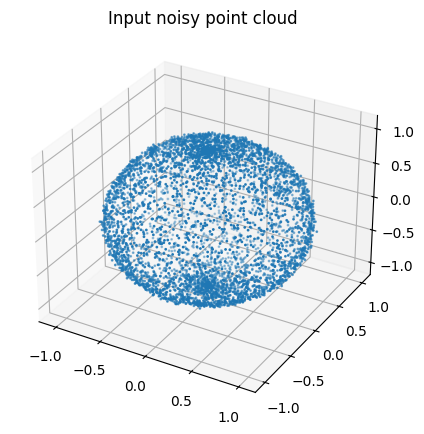

In [2]:
np.random.seed(42)
n = 5000
phi = np.random.uniform(0, 2*np.pi, n)
theta = np.random.uniform(0, np.pi, n)
P = np.column_stack((np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)))
P = P + np.random.normal(0, 0.015, P.shape)

def make_pcd():
    p = o3d.geometry.PointCloud(); p.points = o3d.utility.Vector3dVector(P); return p

pcd = make_pcd()
print('Number of points:', len(pcd.points))
fig = plt.figure(figsize=(5,5)); ax = fig.add_subplot(projection='3d')
ax.scatter(*P.T, s=1); ax.set_title('Input noisy point cloud'); plt.show()

## Task 2: Estimate and display normals
An isolated point has no unique normal: infinitely many planes pass through one point. Normals need a neighbourhood (local PCA plane fit), and the sign is fixed by the orientation step.

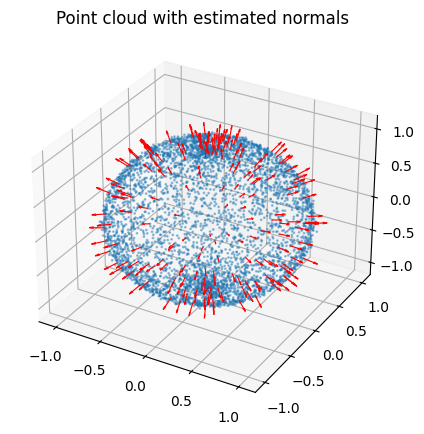

Mean |cos| with true radial normal: 0.993


In [3]:
def normals(radius=0.15, nn=30):
    p = make_pcd()
    p.estimate_normals(search_param=o3d.geometry.KDTreeSearchParamHybrid(radius=radius, max_nn=nn))
    p.orient_normals_consistent_tangent_plane(50)
    return p

def radial_alignment(p):
    N = np.asarray(p.normals)
    return np.abs(np.einsum('ij,ij->i', N, P/np.linalg.norm(P, axis=1, keepdims=True))).mean()

pcd = normals()
N = np.asarray(pcd.normals); idx = np.arange(0, n, 25)
fig = plt.figure(figsize=(5,5)); ax = fig.add_subplot(projection='3d')
ax.scatter(*P.T, s=1, alpha=.4); ax.quiver(*P[idx].T, *(N[idx]*0.15).T, color='r', linewidth=.8)
ax.set_title('Point cloud with estimated normals'); plt.show()
print('Mean |cos| with true radial normal:', round(radial_alignment(pcd), 3))

## Poisson helper + mesh viewer

In [4]:
def poisson(p, depth=9, q=0.02):
    t = time.time()
    m, d = o3d.geometry.TriangleMesh.create_from_point_cloud_poisson(p, depth=depth, width=0, scale=1.1, linear_fit=False)
    el = time.time() - t; v0, t0 = len(m.vertices), len(m.triangles)
    d = np.asarray(d); m.remove_vertices_by_mask(d < np.quantile(d, q))
    m.remove_unreferenced_vertices(); m.compute_vertex_normals()
    R = np.linalg.norm(np.asarray(m.vertices), axis=1)
    info = dict(depth=depth, quantile=q, init_v=v0, init_tri=t0, final_v=len(m.vertices),
                final_tri=len(m.triangles), time_s=round(el,2), radius_mean=round(R.mean(),4), radius_std=round(R.std(),4))
    return m, info

def show_mesh(ax, m, title):
    V = np.asarray(m.vertices); T = np.asarray(m.triangles)
    pc = Poly3DCollection(V[T], linewidths=0, antialiased=False)
    nrm = np.asarray(m.vertex_normals)[T].mean(1); sh = nrm @ np.array([0.4,0.3,0.85])
    sh = (sh - sh.min())/(np.ptp(sh)+1e-9); pc.set_facecolor(plt.cm.viridis(0.25+0.7*sh)); ax.add_collection3d(pc)
    ax.set_xlim(-1.2,1.2); ax.set_ylim(-1.2,1.2); ax.set_zlim(-1.2,1.2); ax.set_title(title, fontsize=9); ax.set_axis_off()

## Task 3: Depth 7 vs 9 vs 10
Depth 9 and 10 are almost identical because 5000 points cannot support a finer octree.

{'depth': 7, 'quantile': 0.02, 'init_v': 15526, 'init_tri': 30936, 'final_v': 15214, 'final_tri': 29816, 'time_s': 0.86, 'radius_mean': np.float64(1.0005), 'radius_std': np.float64(0.0079)}


{'depth': 9, 'quantile': 0.02, 'init_v': 16740, 'init_tri': 33300, 'final_v': 16404, 'final_tri': 32096, 'time_s': 1.21, 'radius_mean': np.float64(1.0005), 'radius_std': np.float64(0.0081)}


{'depth': 10, 'quantile': 0.02, 'init_v': 16739, 'init_tri': 33298, 'final_v': 16403, 'final_tri': 32097, 'time_s': 1.5, 'radius_mean': np.float64(1.0005), 'radius_std': np.float64(0.0081)}


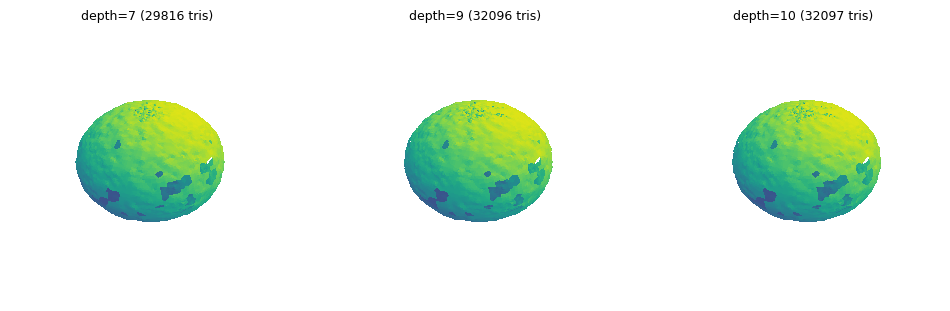

In [5]:
meshes = {}; fig = plt.figure(figsize=(12,4))
for i, d in enumerate((7, 9, 10)):
    m, info = poisson(pcd, depth=d); meshes[d] = m; print(info)
    ax = fig.add_subplot(1,3,i+1,projection='3d'); show_mesh(ax, m, f"depth={d} ({info['final_tri']} tris)")
plt.show()

## Task 4: Normal-estimation radius
Too small (0.03) gives unstable normals and a bad mesh; 0.15 and 0.5 work well for a smooth sphere.

radius=0.03: normal alignment=0.557 {'depth': 8, 'quantile': 0.02, 'init_v': 18990, 'init_tri': 37664, 'final_v': 18610, 'final_tri': 36854, 'time_s': 0.96, 'radius_mean': np.float64(0.9932), 'radius_std': np.float64(0.0436)}


radius=0.15: normal alignment=0.993 {'depth': 8, 'quantile': 0.02, 'init_v': 16844, 'init_tri': 33488, 'final_v': 16506, 'final_tri': 32279, 'time_s': 0.92, 'radius_mean': np.float64(1.0004), 'radius_std': np.float64(0.0081)}


radius=0.5: normal alignment=0.994 {'depth': 8, 'quantile': 0.02, 'init_v': 16844, 'init_tri': 33488, 'final_v': 16506, 'final_tri': 32273, 'time_s': 0.91, 'radius_mean': np.float64(1.0004), 'radius_std': np.float64(0.008)}


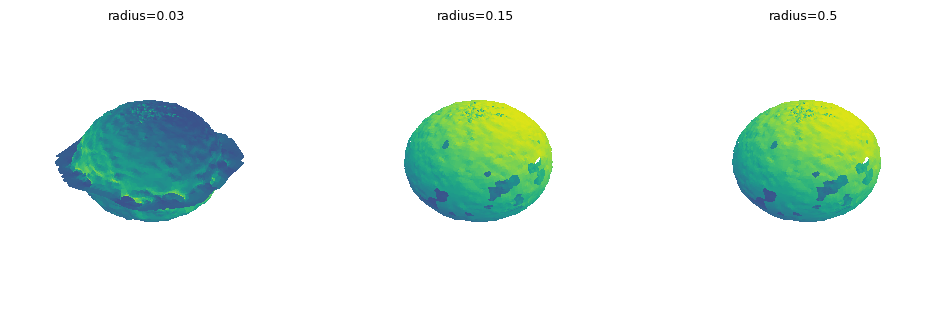

In [6]:
fig = plt.figure(figsize=(12,4))
for i, r in enumerate((0.03, 0.15, 0.5)):
    pr = normals(radius=r); m, info = poisson(pr, depth=8)
    print(f'radius={r}: normal alignment={radial_alignment(pr):.3f}', info)
    ax = fig.add_subplot(1,3,i+1,projection='3d'); show_mesh(ax, m, f'radius={r}')
plt.show()

## Task 5: Density threshold 2% vs 5%
A higher threshold removes more weakly supported vertices: cleaner, but more holes.

In [7]:
for q in (0.02, 0.05):
    m, info = poisson(pcd, depth=9, q=q)
    print(f'{int(q*100)}%:', 'removed', info['init_v']-info['final_v'], 'vertices ->', info['final_tri'], 'triangles')

2%: removed 336 vertices -> 32096 triangles


5%: removed 841 vertices -> 30486 triangles


## Task 6: Save the final mesh as PLY

Saved. Re-read: 16404 vertices, 32096 triangles


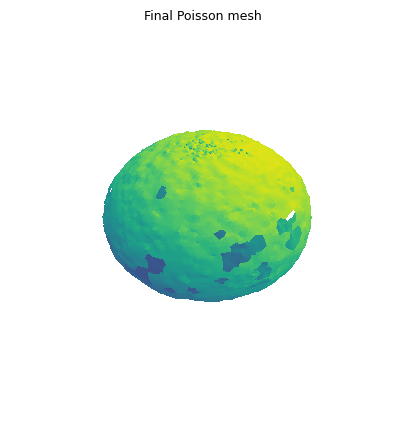

In [8]:
final_mesh, info = poisson(pcd, depth=9, q=0.02)
o3d.io.write_triangle_mesh('poisson_reconstructed_mesh.ply', final_mesh)
chk = o3d.io.read_triangle_mesh('poisson_reconstructed_mesh.ply')
print('Saved. Re-read:', len(chk.vertices), 'vertices,', len(chk.triangles), 'triangles')
fig = plt.figure(figsize=(5,5)); ax = fig.add_subplot(projection='3d'); show_mesh(ax, final_mesh, 'Final Poisson mesh'); plt.show()

## Task 7: Load a real .PLY point cloud
For a real scan, rescale the normal radius to the scan's units/point spacing.

In [9]:
o3d.io.write_point_cloud('input_point_cloud.ply', make_pcd())   # stand-in for a real scan
pcd2 = o3d.io.read_point_cloud('input_point_cloud.ply'); print(pcd2)
pcd2.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=0.15, max_nn=30))
pcd2.orient_normals_consistent_tangent_plane(50)
m2, info2 = poisson(pcd2, depth=9); print(info2)

PointCloud with 5000 points.


{'depth': 9, 'quantile': 0.02, 'init_v': 16740, 'init_tri': 33300, 'final_v': 16404, 'final_tri': 32096, 'time_s': 1.12, 'radius_mean': np.float64(1.0005), 'radius_std': np.float64(0.0081)}


## Task 8: Observations
1. The input is 5000 unconnected noisy samples with positions only: no faces or connectivity.
2. Normals come from local PCA plane fits and are then oriented consistently, giving an oriented point cloud. Bad normals (radius 0.03) damaged the mesh.
3. Poisson solves Δχ = ∇·V for a scalar indicator function χ (high inside, low outside).
4. An isosurface of χ is extracted as ~33,000 connected triangles; vertices lie at radius ≈ 1.000 ± 0.008, so noise is smoothed out.
5. Low-density vertices are removed, vertex normals computed, and the mesh saved as PLY. Depth, normal radius and density threshold control detail, accuracy and cleanliness.